## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen

**Date:** 10/20/2026

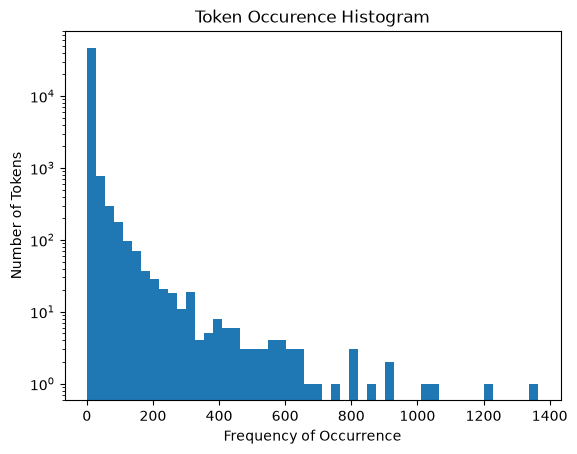

R^2 Test: 0.6571173475409766
R^2 Train: 0.7677733084118992
Top influential words: aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:    0.780070
thermal              0.671019
dtype: float64


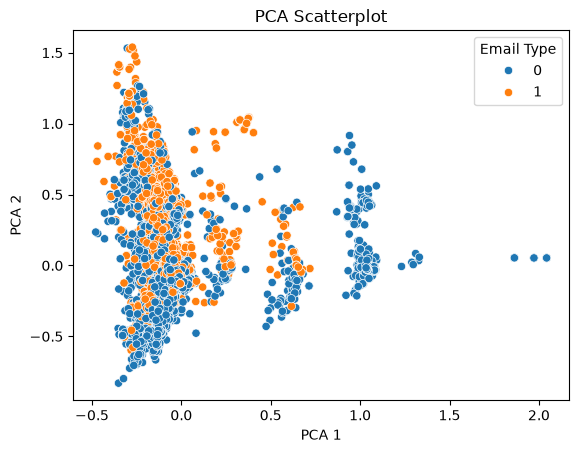

R^2 Test: 0.6613559301353326
R^2 Train: 0.7668967611277832


In [ ]:
# Question 1
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import seaborn as sns

# extract frequencies from tuples in list
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins=50)
plt.yscale("log")
plt.title("Token Occurence Histogram")
plt.xlabel("Frequency of Occurrence")
plt.ylabel("Number of Tokens")
plt.show()

# It looks like the graph has a right skew, meaning that most of the characters have low frequencies. As the token frequency increases, the number of tokens having that frequency decreases exponentially. 

# Question 2

# Load parquet
df = pd.read_parquet("data/Phishing_clean.parquet")
# Split 80/20 train-test
X = df.drop(columns=['Email Type'])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)

# Regression
sk_fit = LinearRegression().fit(X_train, y_train)

# R^2
r_squared_train = sk_fit.score(X_train, y_train)
r_squared_test = sk_fit.score(X_test, y_test)

# R^2 is 0.6571173475409766 on test and 0.7677733084118992 on train
print(f"R^2 Test: {r_squared_test}")
print(f"R^2 Train: {r_squared_train}")

# The top influential words are aging, helvetica, localized, background-image:, and thermal
coefficients = pd.Series(sk_fit.coef_, index=X.columns)
top_coefficients = coefficients.abs().sort_values(ascending=False)
print(f"Top influential words: {top_coefficients.head()}")

# Question 3

# PCA decomposition
pca = PCA(n_components=2).fit(X).transform(X)
pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

# Scatterplot
sns.scatterplot(x="PC1", y="PC2", hue="Email Type", data=pca_df)
plt.title("PCA Scatterplot")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# The pattern in the scatterplot is that the scam and not scam emails overlap in the left side, of lower PCA 1 but as PCA 1 increases, not scam emails become grouped more neatly by themselves. As PCA 2 increases, more scam emails appear but they are not as neatly grouped

# Question 4

# PCA on first 2610
pca = PCA(n_components=2610)
X_train_pca = pca.fit(X_train).transform(X_train)
X_test_pca = pca.transform(X_test)

# Linear regression
pca_model = LinearRegression().fit(X_train_pca, y_train)

# R^2
r_squared_train_pca = pca_model.score(X_train_pca, y_train)
r_squared_test_pca = pca_model.score(X_test_pca, y_test)

# R^2 is 0.6613559301353326 on test and 0.7668967611277832 on train
print(f"R^2 Test: {r_squared_test_pca}")
print(f"R^2 Train: {r_squared_train_pca}")

# The model from question 2 performed about the same to the one in this question. This is because question 2 used 2711 while this one used 2610 components, which although different is still nearly same, making accuracy also almost the same.

# Question 5
# The advantage of using PCA to run high-dimensional regression is that for example in this assignment, there are many words that occur in high frequencies in emails which can make using words to identify if it is a scam hard.
# However, with PCA, it helps reduce that noise to focus on identifying if an email is a scam or not. Additionally, with this much data, PCA also helps shrink it down and make it run faster. 


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]